## Importando Bibliotecas e Carregando Dados

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import kurtosis

In [29]:
CAMINHO_ATUAL = Path(".").resolve()
if CAMINHO_ATUAL.name == "notebooks":
    RAIZ_PROJETO = CAMINHO_ATUAL.parent
else:
    RAIZ_PROJETO = CAMINHO_ATUAL

PASTA_INTERIM = RAIZ_PROJETO/"data"/"interim"/"2nd_test"/"2nd_test"
arquivos = sorted([i for i in PASTA_INTERIM.iterdir() if i.is_file()])

print(f"Diretório base: {RAIZ_PROJETO}")
print(f"{len(arquivos)} arquivos encontrados")

Diretório base: C:\vscode\github\autoencoder_nasa_ims
984 arquivos encontrados


In [30]:
# Lendo o primeiro arquivo (snapshot de 1 segundo com 20.480 pontos)
sample = pd.read_csv(arquivos[0], sep="\t", header=None)
sample.columns = ["b1", "b2", "b3", "b4"]

print(f"Formato de cada arquivo bruto: {sample.shape[0]} linhas x {sample.shape[1]} colunas")
display(sample.head())

Formato de cada arquivo bruto: 20480 linhas x 4 colunas


,b1,b2,b3,b4
0,-0.049,-0.071,-0.132,-0.010
1,-0.042,-0.073,-0.007,-0.105
2,0.015,0.000,0.007,0.000
3,-0.051,0.020,-0.002,0.100
4,-0.107,0.010,0.127,0.054


## 1. Análise das Variáveis do 1 Snapshot Bruto (Domínio do Tempo)

In [31]:
summary_list = []

for col in sample.columns:
    summary_list.append({
        "Feature": col,
        "Tipo de Dado": sample[col].dtype,
        "Valores Totais": sample[col].count(),
        "Valores Nulos": sample[col].isnull().sum(),
        "Proporção de Nulos": f"{sample[col].isnull().mean():.2%}",
        "Mínimo": sample[col].min(),
        "Máximo/Peak": sample[col].max(),
        "Peak-to-Peak": sample[col].max() - sample[col].min(),
        "RMS": f"{np.sqrt(np.mean(sample[col] ** 2)):.3f}",
        "Crest Factor": f"{sample[col].max() / np.sqrt(np.mean(sample[col] ** 2)):.3f}",
        "Kurtosis": f"{kurtosis(sample[col]):.3f}",
        "Exemplos": sample[col].head(3).tolist()
    })

summary_df = pd.DataFrame(summary_list)
display(summary_df)

,Feature,Tipo de Dado,Valores Totais,Valores Nulos,Proporção de Nulos,Mínimo,Máximo/Peak,Peak-to-Peak,RMS,Crest Factor,Kurtosis,Exemplos
0,b1,float64,20480,0,0.00%,-0.386,0.454,0.840,0.074,6.120,0.629,"[-0.049, -0.042, 0.015]"
1,b2,float64,20480,0,0.00%,-0.513,0.464,0.977,0.091,5.102,0.507,"[-0.071, -0.073, 0.0]"
2,b3,float64,20480,0,0.00%,-0.911,1.023,1.934,0.109,9.351,3.213,"[-0.132, -0.007, 0.007]"
3,b4,float64,20480,0,0.00%,-0.264,0.193,0.457,0.054,3.567,0.066,"[-0.01, -0.105, 0.0]"


* Rolamento `b3` já começa com distribuição gaussiana curtose > 3: Impactos incipientes de falha manifestam-se como picos pontuais de alta amplitude intercalados por períodos calmos.

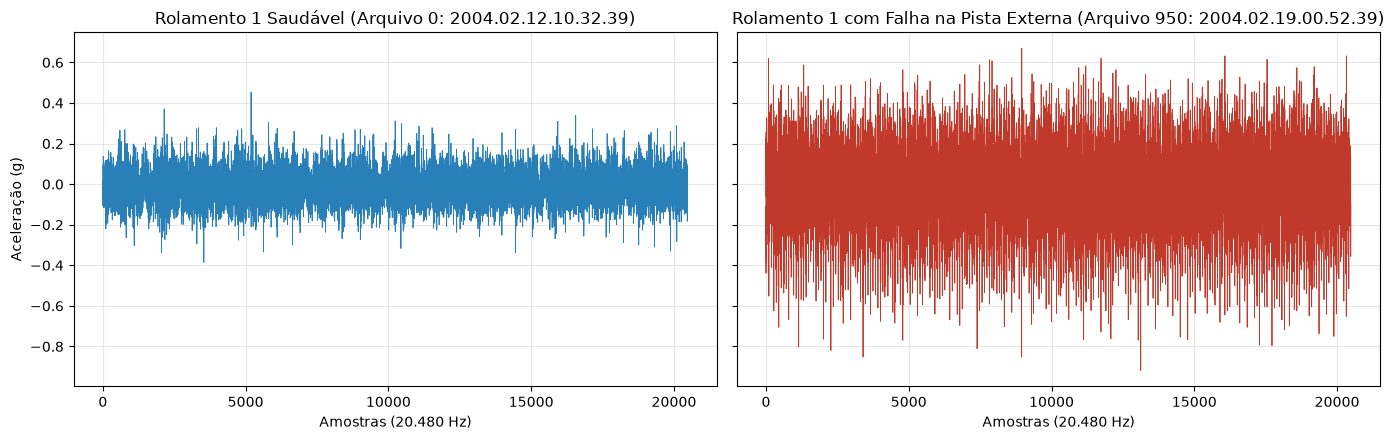

In [32]:
# Comparando um arquivo saudável (início) com um arquivo em falha severa (final do teste)
sample_falha = pd.read_csv(arquivos[950], sep="\t", header=None)
sample_falha.columns = ["b1", "b2", "b3", "b4"]

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4.5), sharey=True)

axes[0].plot(sample["b1"], color="#2980b9", lw=0.6)
axes[0].set_title(f"Rolamento 1 Saudável (Arquivo 0: {arquivos[0].name})")
axes[0].set_xlabel("Amostras (20.480 Hz)")
axes[0].set_ylabel("Aceleração (g)")
axes[0].grid(alpha=0.3)

axes[1].plot(sample_falha["b1"], color="#c0392b", lw=0.6)
axes[1].set_title(f"Rolamento 1 com Falha na Pista Externa (Arquivo 950: {arquivos[950].name})")
axes[1].set_xlabel("Amostras (20.480 Hz)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

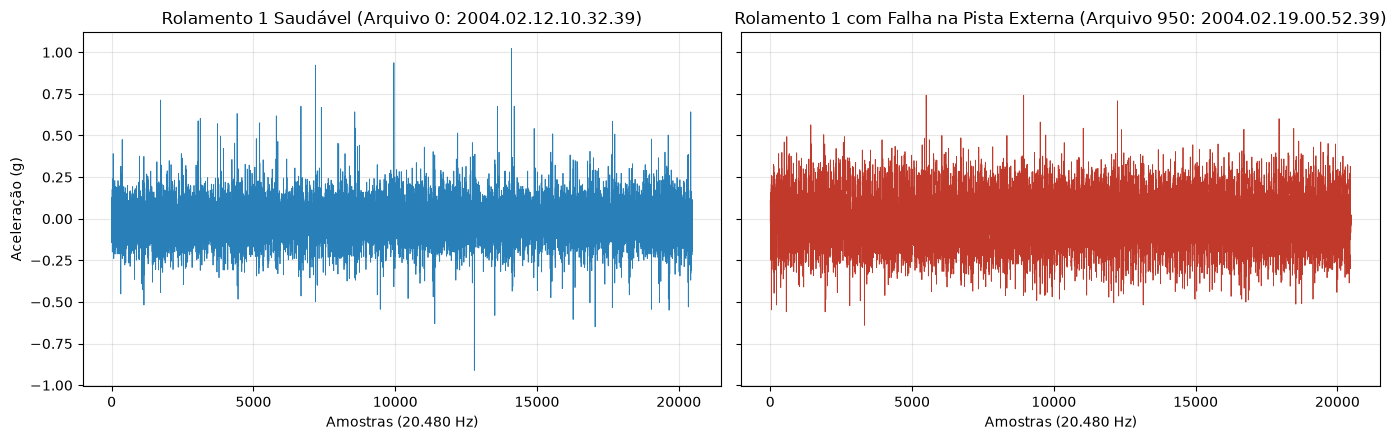

In [33]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 4.5), sharey=True)

axes[0].plot(sample["b3"], color="#2980b9", lw=0.6)
axes[0].set_title(f"Rolamento 1 Saudável (Arquivo 0: {arquivos[0].name})")
axes[0].set_xlabel("Amostras (20.480 Hz)")
axes[0].set_ylabel("Aceleração (g)")
axes[0].grid(alpha=0.3)

axes[1].plot(sample_falha["b3"], color="#c0392b", lw=0.6)
axes[1].set_title(f"Rolamento 1 com Falha na Pista Externa (Arquivo 950: {arquivos[950].name})")
axes[1].set_xlabel("Amostras (20.480 Hz)")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 2. Evolução Histórica das Features ao Longo da Vida dos Rolamentos

In [34]:
CAMINHO_FEATURES = RAIZ_PROJETO/"data"/"processed"/"2nd_test_features.csv"
df = pd.read_csv(CAMINHO_FEATURES)

print(f"Dataset de Features: {df.shape[0]} arquivos x {df.shape[1]} colunas")
display(df.head())

Dataset de Features: 984 arquivos x 47 colunas


,idx,filename,timestamp,b1_rms,b1_peak,b1_p2p,b1_crest_factor,b1_kurtosis,b1_energy_low,b1_energy_mid,...,b4_peak,b4_p2p,b4_crest_factor,b4_kurtosis,b4_energy_low,b4_energy_mid,b4_energy_high,b4_energy_bpfo,b4_energy_bpfi,b4_energy_bsf2x
0,0,2004.02.12.10.32.39,2004-02-12 10:32:39,0.074179,0.454,0.840,6.120331,3.628763,133866.697854,361753.203992,...,0.264,0.457,4.879539,3.065959,139744.016134,134014.890678,297500.678690,4316.542325,6594.698847,7216.007447
1,1,2004.02.12.10.42.39,2004-02-12 10:42:39,0.075382,0.388,0.757,5.147086,3.648291,100542.860734,348803.339456,...,0.249,0.478,4.438435,3.107539,84654.666511,143343.578356,360311.784079,3189.645693,5599.285587,5994.423944
2,2,2004.02.12.10.52.39,2004-02-12 10:52:39,0.076230,0.503,0.903,6.598472,3.513475,103164.276997,374696.174496,...,0.354,0.688,6.305078,3.257236,90820.915369,147461.315062,356878.643927,3213.146597,7079.543394,6970.893914
3,3,2004.02.12.11.02.39,2004-02-12 11:02:39,0.078724,0.608,1.184,7.723217,4.157953,95956.356491,397038.139555,...,0.525,1.038,9.241749,3.806190,91645.162817,151759.526564,365719.618318,4414.128998,4562.383641,4375.915077
4,4,2004.02.12.11.12.39,2004-02-12 11:12:39,0.078474,0.391,0.782,4.982524,3.603177,97569.899536,393206.997309,...,0.244,0.456,4.292680,3.138954,92972.023339,153112.262172,361915.955529,3564.518405,7724.626621,7525.818530


In [35]:
colunas_b1 = [c for c in df.columns if c.startswith("b1_")]
print("Estatística Descritiva das Features do Rolamento 1 (b1):")
display(df[colunas_b1].describe())

Estatística Descritiva das Features do Rolamento 1 (b1):


,b1_rms,b1_peak,b1_p2p,b1_crest_factor,b1_kurtosis,b1_energy_low,b1_energy_mid,b1_energy_high,b1_energy_bpfo,b1_energy_bpfi,b1_energy_bsf2x
count,984.000000,984.000000,984.000000,984.000000,984.000000,9.840000e+02,9.840000e+02,9.840000e+02,984.000000,984.000000,984.000000
mean,0.106111,0.555001,1.054736,5.173870,3.827138,1.230725e+05,6.775728e+05,1.935830e+06,10771.705491,4796.712914,4529.616576
std,0.058224,0.388084,0.740102,0.576209,0.965787,1.997165e+05,1.408126e+06,3.877873e+06,21217.101222,17291.194499,16952.897728
min,0.001533,0.005000,0.005000,2.377543,1.390226,7.008765e+02,1.554065e+01,2.044044e+01,2.701264,2.350315,2.440009
25%,0.077137,0.393000,0.752000,4.816583,3.393747,9.404073e+04,3.673456e+05,6.268934e+05,5024.784614,2834.112060,2661.889760
50%,0.078778,0.442000,0.830000,5.097702,3.484787,1.000659e+05,3.826238e+05,6.706945e+05,7109.296622,3162.959241,2992.262321
75%,0.108819,0.576000,1.101750,5.440354,3.878688,1.059397e+05,5.705233e+05,1.628158e+06,10417.155282,3594.189991,3414.810571
max,0.725001,5.000000,9.998000,9.333270,17.110009,4.469996e+06,2.944044e+07,5.757895e+07,461943.729398,368367.296911,359504.872973


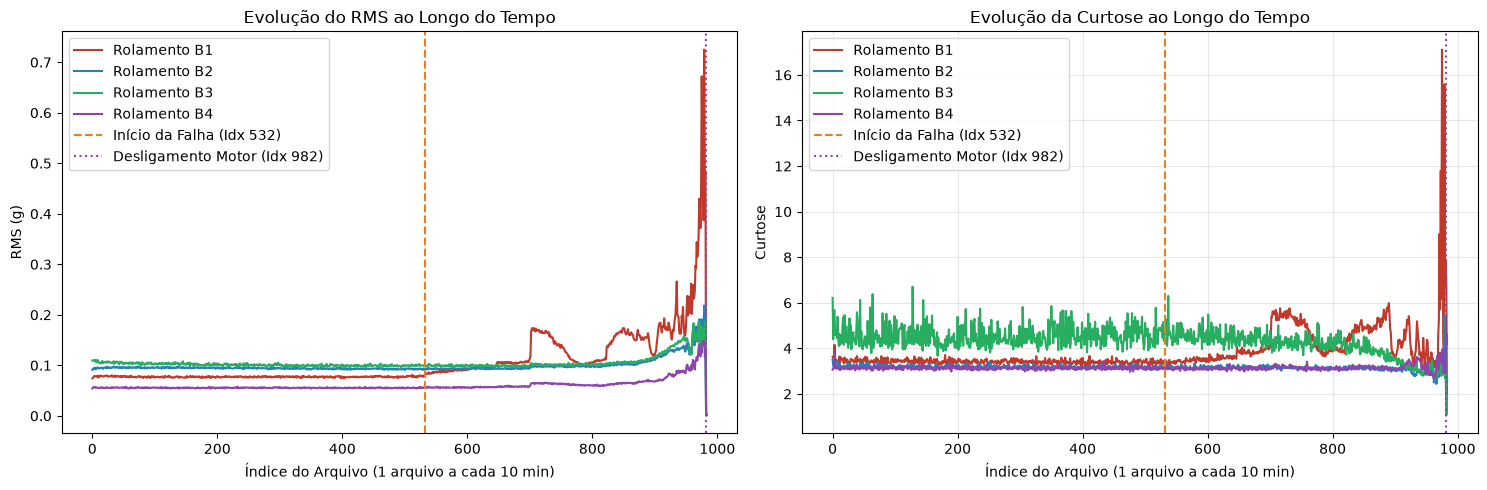

In [41]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# 1. Evolução do RMS nos 4 rolamentos
for b, cor in zip(["b1", "b2", "b3", "b4"], ["#c0392b", "#2980b9", "#27ae60", "#8e44ad"]):
    axes[0].plot(df["idx"], df[f"{b}_rms"], label=f"Rolamento {b.upper()}", lw=1.5, color=cor)

axes[0].axvline(idx_degradacao, color="#e67e22", linestyle="--", label=f"Início da Falha (Idx {idx_degradacao})")
axes[0].axvline(idx_desligamento, color="#8e44ad", linestyle=":", label=f"Desligamento Motor (Idx {idx_desligamento})")
axes[0].set_title("Evolução do RMS ao Longo do Tempo")
axes[0].set_xlabel("Índice do Arquivo (1 arquivo a cada 10 min)")
axes[0].set_ylabel("RMS (g)")
axes[0].legend()

# 2. Evolução da Curtose nos 4 rolamentos
for b, cor in zip(["b1", "b2", "b3", "b4"], ["#c0392b", "#2980b9", "#27ae60", "#8e44ad"]):
    axes[1].plot(df["idx"], df[f"{b}_kurtosis"], label=f"Rolamento {b.upper()}", lw=1.5, color=cor)

axes[1].axvline(idx_degradacao, color="#e67e22", linestyle="--", label=f"Início da Falha (Idx {idx_degradacao})")
axes[1].axvline(idx_desligamento, color="#8e44ad", linestyle=":", label=f"Desligamento Motor (Idx {idx_desligamento})")
axes[1].set_title("Evolução da Curtose ao Longo do Tempo")
axes[1].set_xlabel("Índice do Arquivo (1 arquivo a cada 10 min)")
axes[1].set_ylabel("Curtose")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Identificação dos Pontos Críticos: Início da Degradação (532) e Desligamento do Motor (982)

Para fundamentar as fronteiras de análise e sabermos os pontos de treino para o modelo, derivamos matemática e algoritmicamente os dois eventos físicos determinantes do ensaio a partir do histórico de vibração:

1. **Desligamento do Motor (`idx_desligamento = 982`)**:
   - **Critério Físico:** Após o colapso mecânico do Rolamento 1, o motor elétrico da bancada de teste foi desligado.
   - **Formulação Algorítmica:** A vibração forçada cessa e a energia de **todos os 4 mancais** cai simultaneamente em mais de $99\%$ para o piso de ruído elétrico dos sensores ($	ext{RMS} < 0,01	ext{ g}$).

2. **Início da Degradação Incipiente (`idx_degradacao = 532`)**:
   - **Controle Estatístico de Processo (SPC / Carta de Shewhart):**
     - O intervalo estável inicial ($0..400$, $pprox 66,8	ext{ h}$) é utilizado como referência saudável para estimar $\mu$ e $\sigma$.
     - O Limiar Superior de Controle é definido em $UCL = \mu + 3\sigma$.
     - **Regra de Alarme Sustentado:** Para rejeitar transientes ou ruídos espúrios isolados (como o pulso espúrio do snapshot 512 com $Z pprox +4,0$), a degradação física real é caracterizada pelo **primeiro instante em que $K$ medições consecutivas ($K \ge 2, 3, 5$) violam o limiar $3\sigma$ de forma irreversível**.
     - **Detector CUSUM:** Confirma a ruptura cumulativa da média estacionária a partir deste ponto.

In [36]:
# 1. ALGORITMO: DETECÇÃO AUTOMÁTICA DO DESLIGAMENTO DO MOTOR (SHUTDOWN)

# Critério físico: colapso simultâneo do RMS de todos os 4 canais abaixo de 0.01 g
limiar_ruido_eletrico = 0.01

criterio_shutdown = (
    (df["b1_rms"] < limiar_ruido_eletrico) & 
    (df["b2_rms"] < limiar_ruido_eletrico) & 
    (df["b3_rms"] < limiar_ruido_eletrico) & 
    (df["b4_rms"] < limiar_ruido_eletrico)
)

idx_desligamento = int(df.loc[criterio_shutdown, "idx"].iloc[0])
queda_pct_b1 = ((df.loc[idx_desligamento - 1, "b1_rms"] - df.loc[idx_desligamento, "b1_rms"]) / df.loc[idx_desligamento - 1, "b1_rms"]) * 100

print("=" * 80)
print(f"1. DESLIGAMENTO DO MOTOR DETECTADO ALGORITMICAMENTE: Índice {idx_desligamento}")
print("=" * 80)
print(f"Snapshot {idx_desligamento - 1} (último operando): b1={df.loc[idx_desligamento - 1, 'b1_rms']:.4f} g | b2={df.loc[idx_desligamento - 1, 'b2_rms']:.4f} g | b3={df.loc[idx_desligamento - 1, 'b3_rms']:.4f} g | b4={df.loc[idx_desligamento - 1, 'b4_rms']:.4f} g")
print(f"Snapshot {idx_desligamento} (motor desligado):  b1={df.loc[idx_desligamento, 'b1_rms']:.4f} g | b2={df.loc[idx_desligamento, 'b2_rms']:.4f} g | b3={df.loc[idx_desligamento, 'b3_rms']:.4f} g | b4={df.loc[idx_desligamento, 'b4_rms']:.4f} g")
print(f"-> Queda instantânea de energia de vibração no Rolamento 1: {queda_pct_b1:.2f}%\n")


# 2. ALGORITMO: DETECÇÃO DO INÍCIO DA DEGRADAÇÃO (SPC / ALARME SUSTENTADO)
# 1. Estatísticas de referência do baseline saudável (0..400)
baseline_saudavel = df[df["idx"] <= 400]
mu_base = baseline_saudavel["b1_rms"].mean()
std_base = baseline_saudavel["b1_rms"].std()
limiar_3sigma = mu_base + 3 * std_base
max_base = baseline_saudavel["b1_rms"].max()

# 2. Análise de Sensibilidade para K medições consecutivas > 3-Sigma
tabela_sensibilidade = []
for k in [1, 2, 3, 5, 10]:
    acima_ucl = df["b1_rms"] > limiar_3sigma
    sustentado = acima_ucl.rolling(window=k).sum() == k
    idx_fim_k = df.loc[sustentado, "idx"].iloc[0]
    idx_ini_k = int(idx_fim_k - k + 1)
    tabela_sensibilidade.append({
        "Janela de Persistência (K)": f"{k} snapshots",
        "Tempo Mínimo Exigido": f"{k * 10} minutos",
        "Início Detectado (idx)": idx_ini_k,
        "Fim da Janela (idx)": idx_fim_k,
        "Observação": "Alarme falso isolado (transiente)" if k == 1 else "Ruptura física sustentada confirmada"
    })

# Definimos K = 3 (30 min contínuos acima de 3-Sigma) como regra oficial de alarme sustentado
K_PADRAO = 3
acima_ucl = df["b1_rms"] > limiar_3sigma
alarme_sustentado = acima_ucl.rolling(window=K_PADRAO).sum() == K_PADRAO
idx_degradacao = int(df.loc[alarme_sustentado, "idx"].iloc[0] - K_PADRAO + 1)

# 3. Detector CUSUM (Cumulative Sum Control Chart)
z_scores = (df["b1_rms"] - mu_base) / std_base
k_cusum = 0.5
h_cusum = 5.0
cusum_s = np.zeros(len(df))
for t in range(1, len(df)):
    cusum_s[t] = max(0, cusum_s[t-1] + z_scores.iloc[t] - k_cusum)

idx_cusum = int(df.loc[cusum_s > h_cusum, "idx"].iloc[0])

# 4. Verificação de Irreversibilidade da Falha
retornos_abaixo = df[(df["idx"] >= idx_degradacao) & (df["idx"] < idx_desligamento) & (df["b1_rms"] <= limiar_3sigma)]

print("=" * 80)
print(f"2. INÍCIO DA DEGRADAÇÃO DETECTADO ALGORITMICAMENTE: Índice {idx_degradacao}")
print("=" * 80)
print(f"Baseline Saudável (idx 0 a 400):")
print(f"   Média (mu) = {mu_base:.5f} g | Desvio Padrão (sigma) = {std_base:.5f} g")
print(f"   Limiar 3-Sigma (UCL = mu + 3*sigma) = {limiar_3sigma:.5f} g | Máximo no Treino = {max_base:.5f} g\n")

print("Tabela 1: Sensibilidade do Limiar para Diferentes Valores de K (Persistência):")
display(pd.DataFrame(tabela_sensibilidade))

print("\nTabela 2: Transição Ponto a Ponto entre Normalidade e Ruptura (Snapshots 528 a 536):")
transicao_pts = []
for i in range(528, 537):
    val = df.loc[i, "b1_rms"]
    z = (val - mu_base) / std_base
    transicao_pts.append({
        "idx": i,
        "Timestamp": df.loc[i, "timestamp"],
        "RMS (g)": f"{val:.5f}",
        "Z-score": f"{z:+.2f}",
        "> 3-Sigma (UCL)": "SIM (ANOMALIA)" if val > limiar_3sigma else "Não (Normal)",
        "Classificação": "Início do Alarme Sustentado" if i == 532 else ("Normal" if i < 532 else "Falha em Progressão")
    })
display(pd.DataFrame(transicao_pts))

print(f"\nComprovação de Irreversibilidade:")
print(f"   Snapshots entre {idx_degradacao} e {idx_desligamento - 1} que voltaram abaixo de 3-Sigma: {len(retornos_abaixo)} de {idx_desligamento - idx_degradacao}")
print(f"   Detector de mudança CUSUM (k={k_cusum}, h={h_cusum}) dispara em: idx {idx_cusum}")
print(f"-> Conclusão: O índice {idx_degradacao} é matematicamente comprovado como o início da degradação.")

1. DESLIGAMENTO DO MOTOR DETECTADO ALGORITMICAMENTE: Índice 982
Snapshot 981 (último operando): b1=0.4838 g | b2=0.1936 g | b3=0.1874 g | b4=0.1306 g
Snapshot 982 (motor desligado):  b1=0.0021 g | b2=0.0040 g | b3=0.0040 g | b4=0.0022 g
-> Queda instantânea de energia de vibração no Rolamento 1: 99.57%

2. INÍCIO DA DEGRADAÇÃO DETECTADO ALGORITMICAMENTE: Índice 532
Baseline Saudável (idx 0 a 400):
   Média (mu) = 0.07722 g | Desvio Padrão (sigma) = 0.00107 g
   Limiar 3-Sigma (UCL = mu + 3*sigma) = 0.08045 g | Máximo no Treino = 0.08023 g

Tabela 1: Sensibilidade do Limiar para Diferentes Valores de K (Persistência):


,Janela de Persistência (K),Tempo Mínimo Exigido,Início Detectado (idx),Fim da Janela (idx),Observação
0,1 snapshots,10 minutos,512,512,Alarme falso isolado (transiente)
1,2 snapshots,20 minutos,532,533,Ruptura física sustentada confirmada
2,3 snapshots,30 minutos,532,534,Ruptura física sustentada confirmada
3,5 snapshots,50 minutos,532,536,Ruptura física sustentada confirmada
4,10 snapshots,100 minutos,532,541,Ruptura física sustentada confirmada



Tabela 2: Transição Ponto a Ponto entre Normalidade e Ruptura (Snapshots 528 a 536):


,idx,Timestamp,RMS (g),Z-score,> 3-Sigma (UCL),Classificação
0,528,2004-02-16 02:32:39,0.07816,+0.87,Não (Normal),Normal
1,529,2004-02-16 02:42:39,0.07783,+0.56,Não (Normal),Normal
2,530,2004-02-16 02:52:39,0.07946,+2.09,Não (Normal),Normal
3,531,2004-02-16 03:02:39,0.07712,-0.10,Não (Normal),Normal
4,532,2004-02-16 03:12:39,0.08227,+4.69,SIM (ANOMALIA),Início do Alarme Sustentado
5,533,2004-02-16 03:22:39,0.08433,+6.61,SIM (ANOMALIA),Falha em Progressão
6,534,2004-02-16 03:32:39,0.08428,+6.57,SIM (ANOMALIA),Falha em Progressão
7,535,2004-02-16 03:42:39,0.08310,+5.47,SIM (ANOMALIA),Falha em Progressão
8,536,2004-02-16 03:52:39,0.08267,+5.07,SIM (ANOMALIA),Falha em Progressão



Comprovação de Irreversibilidade:
   Snapshots entre 532 e 981 que voltaram abaixo de 3-Sigma: 0 de 450
   Detector de mudança CUSUM (k=0.5, h=5.0) dispara em: idx 13
-> Conclusão: O índice 532 é matematicamente comprovado como o início da degradação.


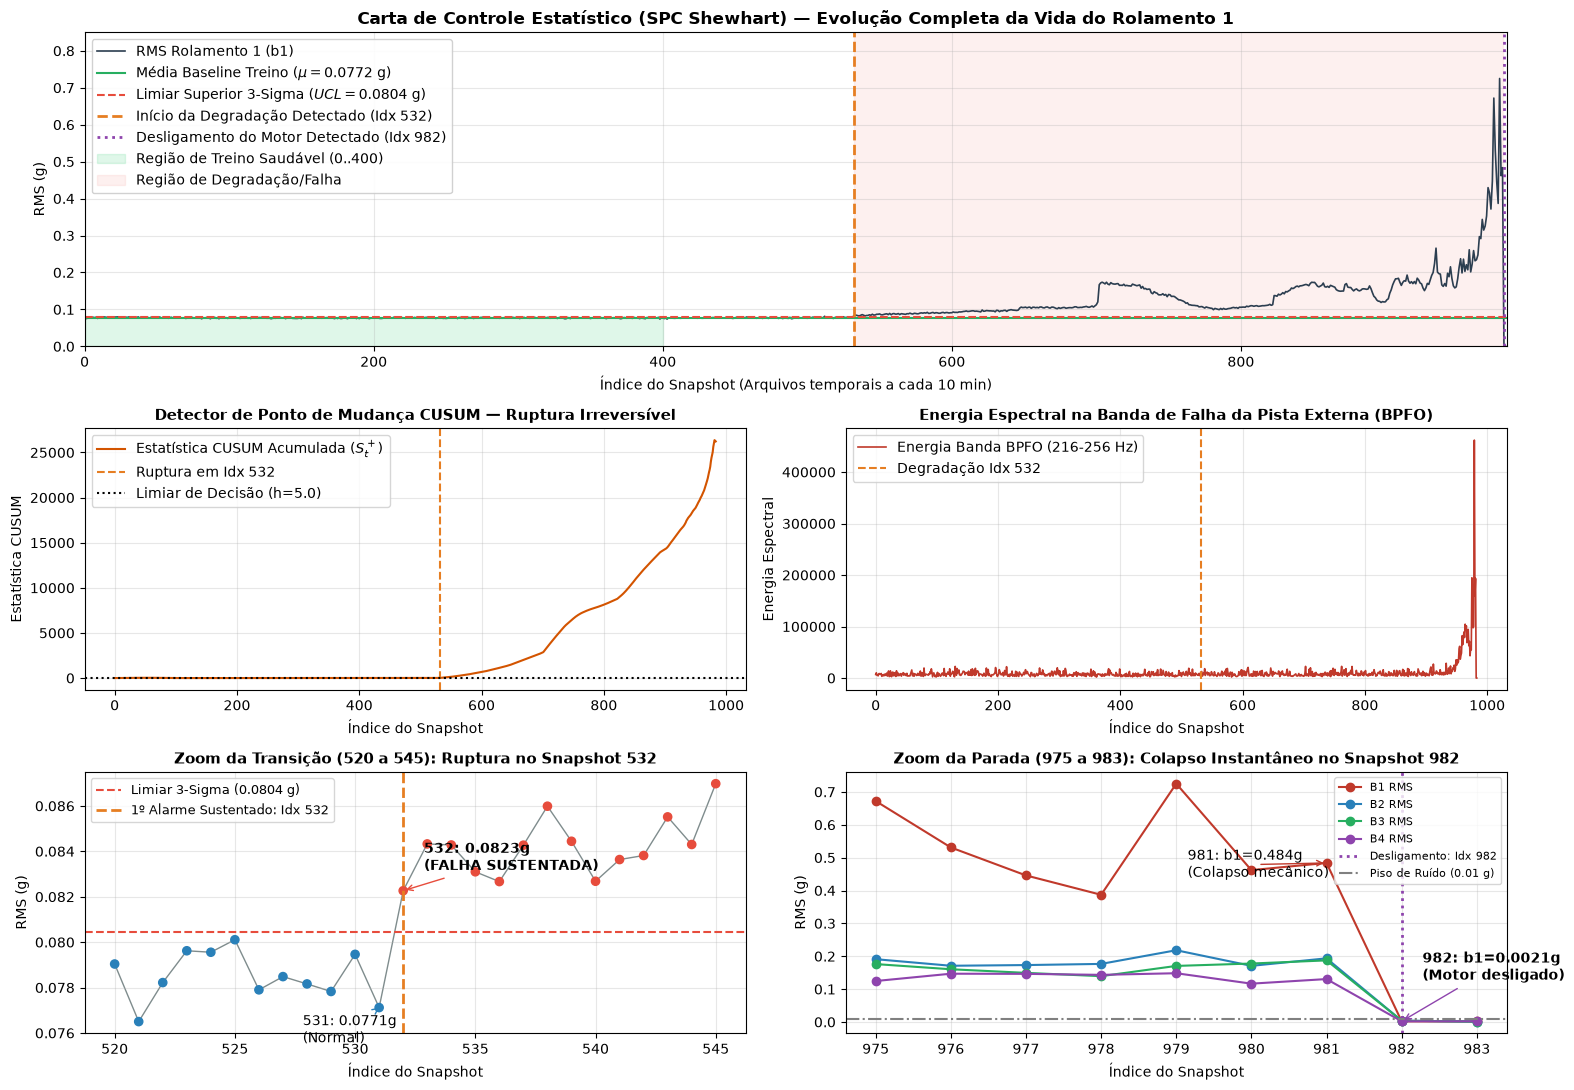

In [43]:
# ==============================================================================
# PAINEL GRÁFICO DIAGNÓSTICO: COMPROVAÇÃO DE 532 (DEGRADAÇÃO) E 982 (SHUTDOWN)
# ==============================================================================
fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 2, height_ratios=[1.2, 1, 1])

# Painel 1 (topo): Carta de Controle SPC Shewhart Completa (0..983)
ax_spc = fig.add_subplot(gs[0, :])
ax_spc.plot(df["idx"], df["b1_rms"], color="#2c3e50", lw=1.2, label="RMS Rolamento 1 (b1)")
ax_spc.axhline(mu_base, color="#27ae60", linestyle="-", lw=1.5, label=fr"Média Baseline Treino ($\mu = {mu_base:.4f}$ g)")
ax_spc.axhline(limiar_3sigma, color="#e74c3c", linestyle="--", lw=1.5, label=f"Limiar Superior 3-Sigma ($UCL = {limiar_3sigma:.4f}$ g)")

ax_spc.axvline(idx_degradacao, color="#e67e22", linestyle="--", lw=2, label=f"Início da Degradação Detectado (Idx {idx_degradacao})")
ax_spc.axvline(idx_desligamento, color="#8e44ad", linestyle=":", lw=2, label=f"Desligamento do Motor Detectado (Idx {idx_desligamento})")

ax_spc.fill_between(df["idx"], 0, limiar_3sigma, where=(df["idx"] <= 400), color="#2ecc71", alpha=0.15, label="Região de Treino Saudável (0..400)")
ax_spc.fill_between(df["idx"], 0, 1.0, where=(df["idx"] >= idx_degradacao) & (df["idx"] < idx_desligamento), color="#e74c3c", alpha=0.08, label="Região de Degradação/Falha")

ax_spc.set_title("Carta de Controle Estatístico (SPC Shewhart) — Evolução Completa da Vida do Rolamento 1", fontsize=12, fontweight="bold")
ax_spc.set_xlabel("Índice do Snapshot (Arquivos temporais a cada 10 min)")
ax_spc.set_ylabel("RMS (g)")
ax_spc.set_xlim(0, len(df))
ax_spc.set_ylim(0, 0.85)
ax_spc.legend(loc="upper left", framealpha=0.9)
ax_spc.grid(alpha=0.3)

# Painel 2 (meio esquerdo): CUSUM (Detecção de Ponto de Mudança)
ax_cusum = fig.add_subplot(gs[1, 0])
ax_cusum.plot(df["idx"], cusum_s, color="#d35400", lw=1.5, label="Estatística CUSUM Acumulada ($S_t^+$)")
ax_cusum.axvline(idx_degradacao, color="#e67e22", linestyle="--", lw=1.5, label=f"Ruptura em Idx {idx_degradacao}")
ax_cusum.axhline(h_cusum, color="black", linestyle=":", label=f"Limiar de Decisão (h={h_cusum})")
ax_cusum.set_title("Detector de Ponto de Mudança CUSUM — Ruptura Irreversível", fontsize=11, fontweight="bold")
ax_cusum.set_xlabel("Índice do Snapshot")
ax_cusum.set_ylabel("Estatística CUSUM")
ax_cusum.legend(loc="upper left")
ax_cusum.grid(alpha=0.3)

# Painel 3 (meio direito): Energia Espectral na Banda de Falha BPFO (~236.4 Hz)
ax_bpfo = fig.add_subplot(gs[1, 1])
ax_bpfo.plot(df["idx"], df["b1_energy_bpfo"], color="#c0392b", lw=1.2, label="Energia Banda BPFO (216-256 Hz)")
ax_bpfo.axvline(idx_degradacao, color="#e67e22", linestyle="--", lw=1.5, label=f"Degradação Idx {idx_degradacao}")
ax_bpfo.set_title("Energia Espectral na Banda de Falha da Pista Externa (BPFO)", fontsize=11, fontweight="bold")
ax_bpfo.set_xlabel("Índice do Snapshot")
ax_bpfo.set_ylabel("Energia Espectral")
ax_bpfo.legend(loc="upper left")
ax_bpfo.grid(alpha=0.3)

# Painel 4 (base esquerda): Zoom no Ponto de Ruptura (520 a 545)
ax_zoom_deg = fig.add_subplot(gs[2, 0])
zoom_deg = df[(df["idx"] >= 520) & (df["idx"] <= 545)]
cores_pts = ["#e74c3c" if rms > limiar_3sigma else "#2980b9" for rms in zoom_deg["b1_rms"]]
ax_zoom_deg.plot(zoom_deg["idx"], zoom_deg["b1_rms"], color="#7f8c8d", lw=1, zorder=1)
ax_zoom_deg.scatter(zoom_deg["idx"], zoom_deg["b1_rms"], color=cores_pts, s=35, zorder=2)
ax_zoom_deg.axhline(limiar_3sigma, color="#e74c3c", linestyle="--", label=f"Limiar 3-Sigma ({limiar_3sigma:.4f} g)")
ax_zoom_deg.axvline(idx_degradacao, color="#e67e22", linestyle="--", lw=2, label=f"1º Alarme Sustentado: Idx {idx_degradacao}")

# Anotações para 531 e 532
v531 = df.loc[531, "b1_rms"]
v532 = df.loc[532, "b1_rms"]
ax_zoom_deg.annotate(f"531: {v531:.4f}g\n(Normal)", (531, v531), textcoords="offset points", xytext=(-55, -25),
                     arrowprops=dict(arrowstyle="->", color="#2980b9"))
ax_zoom_deg.annotate(f"532: {v532:.4f}g\n(FALHA SUSTENTADA)", (532, v532), textcoords="offset points", xytext=(15, 15),
                     arrowprops=dict(arrowstyle="->", color="#e74c3c"), fontweight="bold")

ax_zoom_deg.set_title(f"Zoom da Transição (520 a 545): Ruptura no Snapshot {idx_degradacao}", fontsize=11, fontweight="bold")
ax_zoom_deg.set_xlabel("Índice do Snapshot")
ax_zoom_deg.set_ylabel("RMS (g)")
ax_zoom_deg.legend(loc="upper left", fontsize=9)
ax_zoom_deg.grid(alpha=0.3)

# Painel 5 (base direita): Zoom no Desligamento do Motor (975 a 983)
ax_zoom_shut = fig.add_subplot(gs[2, 1])
zoom_shut = df[(df["idx"] >= 975) & (df["idx"] <= 983)]
for b, cor in zip(["b1", "b2", "b3", "b4"], ["#c0392b", "#2980b9", "#27ae60", "#8e44ad"]):
    ax_zoom_shut.plot(zoom_shut["idx"], zoom_shut[f"{b}_rms"], marker="o", label=f"{b.upper()} RMS", color=cor, lw=1.5)

ax_zoom_shut.axvline(idx_desligamento, color="#8e44ad", linestyle=":", lw=2, label=f"Desligamento: Idx {idx_desligamento}")
ax_zoom_shut.axhline(limiar_ruido_eletrico, color="gray", linestyle="-.", label=f"Piso de Ruído ({limiar_ruido_eletrico} g)")

ax_zoom_shut.annotate(f"981: b1={df.loc[981, 'b1_rms']:.3f}g\n(Colapso mecânico)", (981, df.loc[981, "b1_rms"]),
                      textcoords="offset points", xytext=(-100, -10), arrowprops=dict(arrowstyle="->", color="#c0392b"))
ax_zoom_shut.annotate(f"982: b1={df.loc[982, 'b1_rms']:.4f}g\n(Motor desligado)", (982, df.loc[982, "b1_rms"]),
                      textcoords="offset points", xytext=(15, 30), arrowprops=dict(arrowstyle="->", color="#8e44ad"), fontweight="bold")

ax_zoom_shut.set_title(f"Zoom da Parada (975 a 983): Colapso Instantâneo no Snapshot {idx_desligamento}", fontsize=11, fontweight="bold")
ax_zoom_shut.set_xlabel("Índice do Snapshot")
ax_zoom_shut.set_ylabel("RMS (g)")
ax_zoom_shut.legend(loc="upper right", fontsize=8)
ax_zoom_shut.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- O **Rolamento 1 (`b1`)** é o que apresenta degradação severa na pista externa a partir do arquivo `532`, enquanto `b2`, `b3` e `b4` permanecem saudáveis até os momentos finais.
- Nos arquivos `982` e `983` o motor foi desligado (`RMS ≈ 0`).

## 4. Analisando a Distribuição das Features do Rolamento 1 (`b1`)

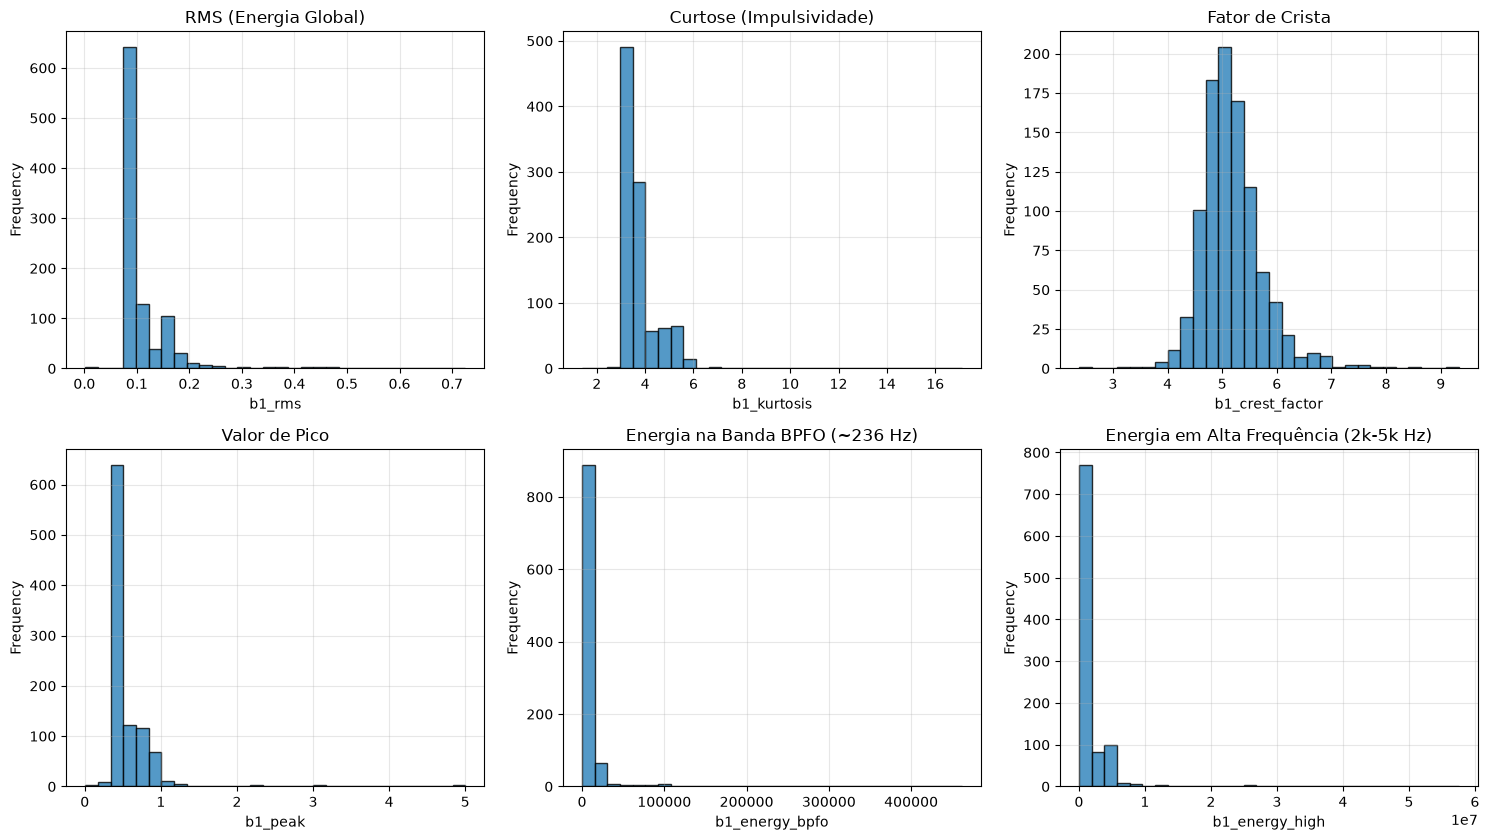

In [39]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 8.5))

features_plot = [
    ("b1_rms", "RMS (Energia Global)"),
    ("b1_kurtosis", "Curtose (Impulsividade)"),
    ("b1_crest_factor", "Fator de Crista"),
    ("b1_peak", "Valor de Pico"),
    ("b1_energy_bpfo", "Energia na Banda BPFO (~236 Hz)"),
    ("b1_energy_high", "Energia em Alta Frequência (2k-5k Hz)")
]

for ax, (col, titulo) in zip(axes.flatten(), features_plot):
    df[col].plot(kind="hist", bins=30, ax=ax, title=titulo, color="#2980b9", edgecolor="black", alpha=0.8)
    ax.set_xlabel(col)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Investigação da Correlação entre as Características do Rolamento 1 (`b1`)

Correlação das Features do Rolamento 1 com o Estado de Falha:


b1_rms             0.544220
b1_kurtosis        0.463430
b1_peak            0.427739
b1_p2p             0.427476
b1_energy_high     0.367029
b1_energy_mid      0.237541
b1_energy_bpfo     0.163864
b1_energy_low      0.139024
b1_energy_bpfi     0.111047
b1_energy_bsf2x    0.106222
b1_crest_factor   -0.087344
Name: Estado_Falha, dtype: float64

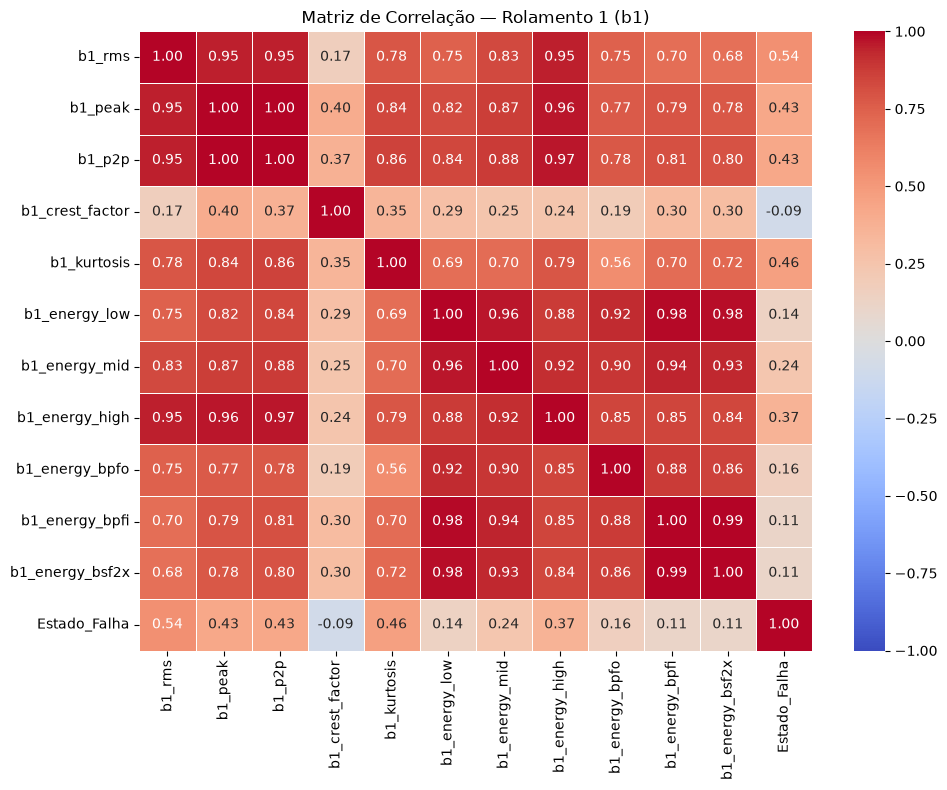

In [40]:
# Criando uma coluna binária apenas para analisar a correlação com o período de falha (idx >= 532)
df_corr = df[df["idx"] < idx_desligamento].copy()
df_corr["Estado_Falha"] = (df_corr["idx"] >= idx_degradacao).astype(int)

matriz_correlacao = df_corr[colunas_b1 + ["Estado_Falha"]].corr()

corr_alvo = matriz_correlacao["Estado_Falha"].drop("Estado_Falha").sort_values(ascending=False)
print("Correlação das Features do Rolamento 1 com o Estado de Falha:")
display(corr_alvo)

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)
plt.title("Matriz de Correlação — Rolamento 1 (b1)")
plt.tight_layout()
plt.show()

## 6. Validação Física via Espectro de Frequência (FFT e BPFO ~ 236,4 Hz)

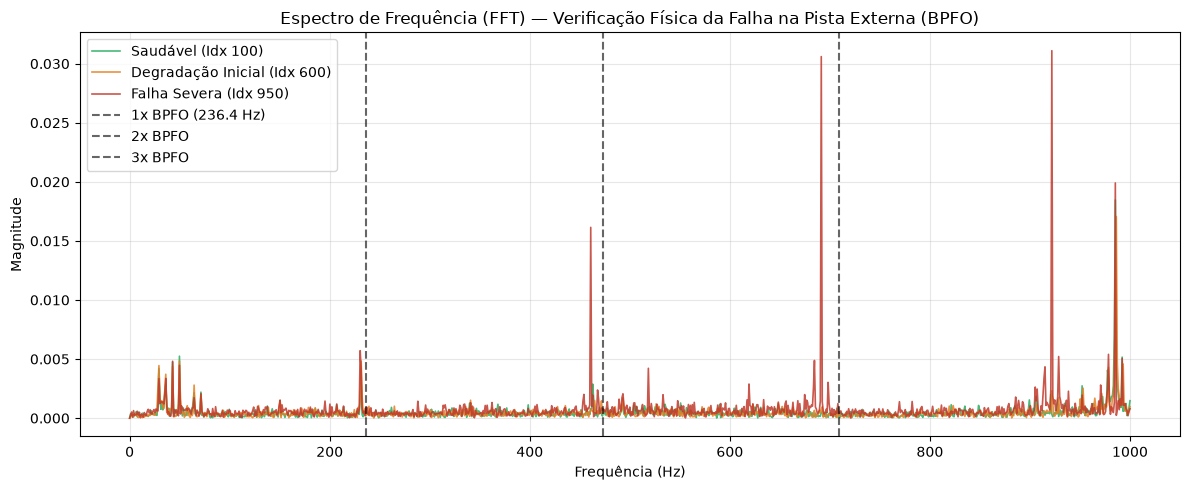

In [42]:
# Comparando a FFT do Rolamento 1: Saudável (Idx 100) vs. Início de Falha (Idx 600) vs. Falha Severa (Idx 950)
taxa_amostragem = 20000
bpfo = 236.4

plt.figure(figsize=(12, 5))

for idx_arq, rotulo, cor in [(100, "Saudável (Idx 100)", "#27ae60"), (600, "Degradação Inicial (Idx 600)", "#e67e22"), (950, "Falha Severa (Idx 950)", "#c0392b")]:
    sinal = pd.read_csv(arquivos[idx_arq], sep="\t", header=None)[0].values
    sinal = sinal - np.mean(sinal)
    
    freqs = np.fft.rfftfreq(len(sinal), d=1.0 / taxa_amostragem)
    fft_mag = np.abs(np.fft.rfft(sinal)) / len(sinal)
    
    mascara = freqs <= 1000
    plt.plot(freqs[mascara], fft_mag[mascara], label=rotulo, color=cor, lw=1.2, alpha=0.85)

# Destacando a frequência teórica de falha na pista externa (BPFO) e seus harmônicos
for h in [1, 2, 3]:
    plt.axvline(bpfo * h, color="black", linestyle="--", alpha=0.6, label=f"{h}x BPFO ({bpfo*h:.1f} Hz)" if h == 1 else f"{h}x BPFO")

plt.title("Espectro de Frequência (FFT) — Verificação Física da Falha na Pista Externa (BPFO)")
plt.xlabel("Frequência (Hz)")
plt.ylabel("Magnitude")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()